# 4. Convex functions

Portfolio exercises 4.1–4.6. Each exercise tests one of the characterisations of
convexity from [CO 6]–[CO 9]: chords and epigraphs (4.1), Hessian eigenvalues on
a grid (4.2), convexity along rays for $-\log\det$ (4.3), the eigenvalue
functions as suprema of linear functions (4.4), the linear function
$\operatorname{tr}(SX)$ on the PSD cone and the Gaussian likelihood (4.5), and
the operations that preserve convexity plus Jensen's inequality (4.6).

Every identity is checked numerically next to where it is used, and every
figure is referred to in the text. All random experiments use
rng = np.random.default_rng(2026).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.special import logsumexp

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})

## 4.1 Chords, tangents and epigraphs [CO 6.1, 7.1, 7.2]

### Task

For $e^{ax}$, $-\log x$, $x\log x$, $x^a$ (on $x>0$) and $|x|$, plot the
function, a few chords $\lambda f(x)+(1-\lambda)f(y)$ and a few tangents
$f(x_0)+f'(x_0)(x-x_0)$, and shade the epigraph.

### Explore

Move $a$ in $x^a$ through $-1,\,0,\,0.5,\,1,\,2$. Add $\sin x$ and $x^3$.

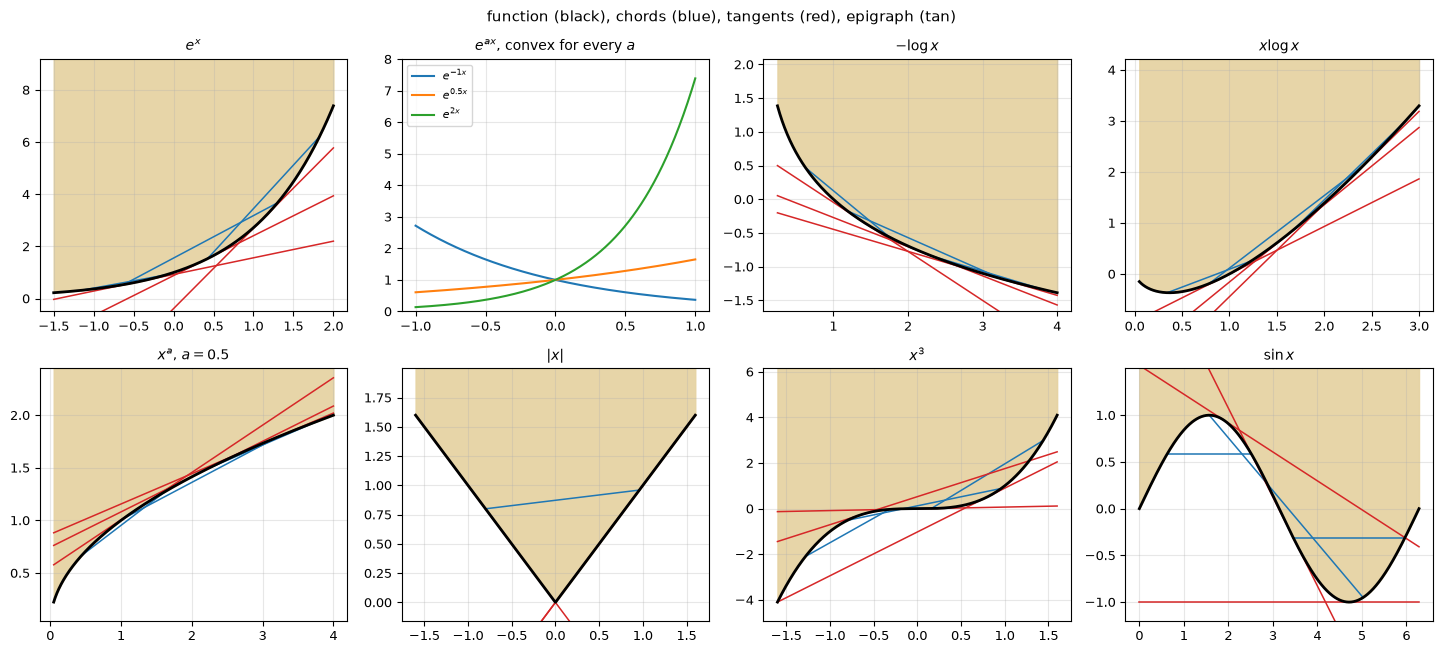

In [2]:
def curve_panel(ax, f, fp, lo, hi, label, pad=0.25):
    """Function (black), three chords (blue), three tangents (red), epigraph (tan)."""
    xs = np.linspace(lo, hi, 600)
    ys = f(xs)
    span = max(ys.max() - ys.min(), 1.0)
    top = ys.max() + pad * span
    ax.fill_between(xs, ys, top, color="#e6d3a3", alpha=0.95, zorder=0)
    ax.plot(xs, ys, "k-", lw=2, zorder=3)
    w = hi - lo
    for x1, x2 in [(lo + 0.10*w, lo + 0.40*w), (lo + 0.25*w, lo + 0.80*w),
                   (lo + 0.55*w, hi - 0.05*w)]:
        lam = np.linspace(0, 1, 200)
        ax.plot(lam*x1 + (1-lam)*x2, lam*f(x1) + (1-lam)*f(x2),
                color="tab:blue", lw=1.1, zorder=2)
    for x0 in (lo + 0.30*w, lo + 0.55*w, lo + 0.75*w):
        ax.plot(xs, f(x0) + fp(x0)*(xs - x0), color="tab:red", lw=1.1, zorder=2)
    ax.set_ylim(ys.min() - 0.10*span, top)
    ax.set_title(label, fontsize=10)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.6))
curve_panel(axes[0, 0], np.exp, np.exp, -1.5, 2.0, r"$e^{x}$")
ax = axes[0, 1]
xf1 = np.linspace(-1.0, 1.0, 400)
for av in (-1.0, 0.5, 2.0):
    ax.plot(xf1, np.exp(av*xf1), label=fr"$e^{{{av:g}x}}$")
ax.set_ylim(0, 8); ax.legend(fontsize=8)
ax.set_title(r"$e^{ax}$, convex for every $a$", fontsize=10)
curve_panel(axes[0, 2], lambda t: -np.log(t), lambda t: -1/t, 0.25, 4.0, r"$-\log x$")
curve_panel(axes[0, 3], lambda t: t*np.log(t), lambda t: np.log(t)+1, 0.05, 3.0, r"$x\log x$")
curve_panel(axes[1, 0], np.sqrt, lambda t: 0.5/np.sqrt(t), 0.05, 4.0, r"$x^{a}$, $a=0.5$")
curve_panel(axes[1, 1], np.abs, np.sign, -1.6, 1.6, r"$|x|$")
curve_panel(axes[1, 2], lambda t: t**3, lambda t: 3*t**2, -1.6, 1.6, r"$x^{3}$")
curve_panel(axes[1, 3], np.sin, np.cos, 0.0, 2*np.pi, r"$\sin x$")
fig.suptitle("function (black), chords (blue), tangents (red), epigraph (tan)", fontsize=11)
fig.tight_layout()
plt.show()

a =   -1:  f'' in [0.25, 31.25] on (0.4, 2)  ->  f'' > 0: convex
a =    0:  f'' in [-0, -0] on (0.4, 2)  ->  f'' = 0: linear (convex and concave)
a =  0.5:  f'' in [-0.9882, -0.08839] on (0.4, 2)  ->  f'' < 0: concave
a =    1:  f'' in [0, 0] on (0.4, 2)  ->  f'' = 0: linear (convex and concave)
a =    2:  f'' in [2, 2] on (0.4, 2)  ->  f'' > 0: convex


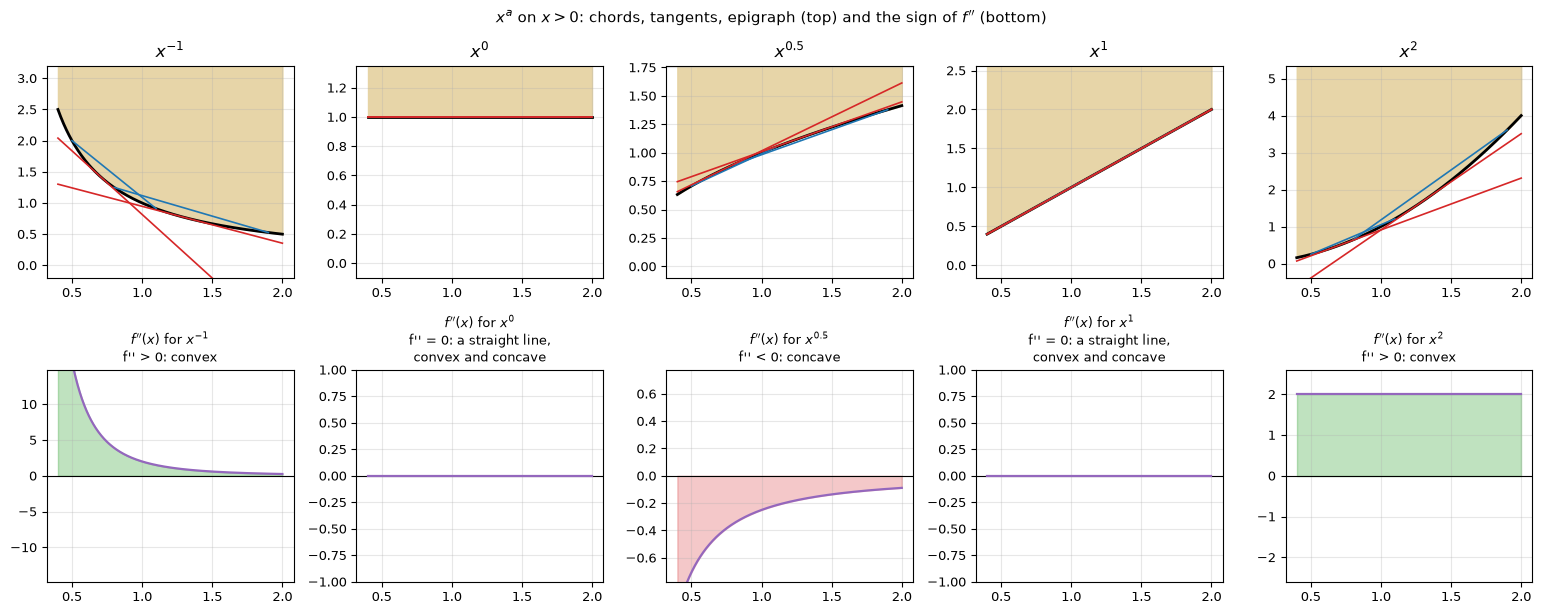

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.2))
a_vals = [-1.0, 0.0, 0.5, 1.0, 2.0]
xf = np.linspace(0.4, 2.0, 400)
for j, a in enumerate(a_vals):
    f = lambda t, a=a: t**a
    fp = lambda t, a=a: a * t**(a - 1)
    fpp = lambda t, a=a: a * (a - 1) * t**(a - 2)
    y = f(xf)
    span = max(y.max() - y.min(), 1.0)
    ax = axes[0, j]
    ax.fill_between(xf, y, y.max() + 0.35*span, color="#e6d3a3", alpha=0.95, zorder=0)
    ax.plot(xf, y, "k-", lw=2)
    for x1, x2 in [(0.5, 1.1), (0.8, 1.9)]:
        lam = np.linspace(0, 1, 100)
        ax.plot(lam*x1 + (1-lam)*x2, lam*f(x1) + (1-lam)*f(x2), color="tab:blue", lw=1.2)
    for x0 in (0.7, 1.3):
        ax.plot(xf, f(x0) + fp(x0)*(xf-x0), color="tab:red", lw=1.2)
    ax.set_title(fr"$x^{{{a:g}}}$", fontsize=12)
    ax.set_ylim(min(y.min(), 0) - 0.1*span, y.max() + 0.35*span)

    # bottom row: the second-derivative test [CO 7.2]; green where f'' > 0, red where f'' < 0
    c = fpp(xf)
    ax = axes[1, j]
    ax.axhline(0, color="k", lw=0.8)
    ax.plot(xf, c, color="tab:purple", lw=1.6)
    ax.fill_between(xf, c, 0, where=(c > 0), color="tab:green", alpha=0.30, interpolate=True)
    ax.fill_between(xf, c, 0, where=(c < 0), color="tab:red", alpha=0.25, interpolate=True)
    if np.allclose(c, 0, atol=1e-12):
        ax.set_ylim(-1, 1)
        verdict = "f'' = 0: a straight line,\nconvex and concave"
        short = "f'' = 0: linear (convex and concave)"
    else:
        lim = 1.3 * np.percentile(np.abs(c), 90)
        ax.set_ylim(-lim, lim)
        verdict = "f'' > 0: convex" if np.all(c >= -1e-12) else "f'' < 0: concave"
        short = verdict
    ax.set_title(fr"$f''(x)$ for $x^{{{a:g}}}$" + "\n" + verdict, fontsize=9.5)
    print(f"a = {a:>4g}:  f'' in [{c.min():.4g}, {c.max():.4g}] on (0.4, 2)  ->  "
          f"{short}")
fig.suptitle(r"$x^a$ on $x>0$: chords, tangents, epigraph (top) and the sign of $f''$ (bottom)",
             fontsize=11)
fig.tight_layout()
plt.show()

for a, sgn in [(-1.0, +1), (2.0, +1), (0.5, -1)]:
    assert np.all(sgn * a * (a - 1) * xf**(a - 2) >= -1e-12)

In [4]:
import ipywidgets as widgets
from IPython.display import display


def show_slider(draw, slider):
    """One slider and one figure area, redrawn in place on every change."""
    out = widgets.Output()

    def on_change(change):
        with out:
            out.clear_output(wait=True)
            draw(change["new"])

    slider.observe(on_change, names="value")
    display(widgets.VBox([slider, out]))
    with out:
        draw(slider.value)


def draw_xa(a):
    xs = np.linspace(0.35, 2.0, 200)
    ys = xs**a
    fig, ax = plt.subplots(figsize=(6.0, 3.4))
    ax.fill_between(xs, ys, 8.0, color="#e6d3a3", alpha=0.95)
    ax.plot(xs, ys, "k-", lw=2)
    lam = np.linspace(0, 1, 60)
    ax.plot(lam*0.5 + (1-lam)*1.2, lam*0.5**a + (1-lam)*1.2**a, color="tab:blue", lw=1.3)
    for x0 in (0.7, 1.3):
        ax.plot(xs, x0**a + a*x0**(a-1)*(xs-x0), color="tab:red", lw=1.3)
    ax.set_ylim(0, 8)
    ax.set_title(fr"$x^a$, $a={a:g}$: $f''(x)=a(a-1)x^{{a-2}}$")
    plt.show()


# continuous_update=False: one redraw when the mouse is released, not one per pixel
show_slider(draw_xa, widgets.FloatSlider(value=0.5, min=-1.0, max=3.0, step=0.1,
                                         description="$a$", continuous_update=False))

### Explain

- A function is convex if chords are above the graph, tangents below and $f''(x)\ge0$.
- A function is concave if chords are below the graph, tangents above and $f''(x)\le0$.
- A function is both when chords and tangents are in the graph and $f''(x)\equiv0$.

For $x^a$, $f''(x)=a(a-1)x^{a-2}$ has the sign of $a(a-1)$: convex for $a\le0$
or $a\ge1$, concave for $0\le a\le1$, and *both* only at $a=0$ and
$a=1$, where $f''\equiv0$ and the graph is a straight line.


## 4.2 Convexity in $\mathbb{R}^2$: Hessian test [CO 7.2, 8.1, 8.2, 9.4]

### Task

Plot surfaces and contours of $\|x\|_1$, $\|x\|_2$, $\|x\|_\infty$,
$\max(x_1,x_2)$, the log-sum-exp $\log(e^{x_1}+e^{x_2})$, $\|Ax+b\|_2^2$ and
$f(x)=x_1x_2$. Where defined, compute the eigenvalues of the Hessian on a grid
and colour each point by $\lambda_{\min}(H_f)$.

### Explore

Show along the ray $(0,0)+t(1,-1)$ that $x_1x_2$ is not convex, even though it
is convex in each variable separately [CO 9.4]. Check numerically which sign of
the log-sum-exp is convex, since [CO 8.2] prints a minus sign.

In [5]:
A2 = np.array([[1.0, 0.5], [-0.3, 0.8]])
b2 = np.array([0.2, -0.4])


def hess_fd(f, p, h=2e-4):
    """Central-difference Hessian of f at p (2-vector)."""
    e = np.eye(2)
    H = np.zeros((2, 2))
    for i in range(2):
        for j in range(2):
            H[i, j] = (f(p + h*e[i] + h*e[j]) - f(p + h*e[i] - h*e[j])
                       - f(p - h*e[i] + h*e[j]) + f(p - h*e[i] - h*e[j])) / (4*h*h)
    return H


def lam_min_grid(f, X, Y, h=2e-4, tol=1e-2):
    """lambda_min(H_f) on a grid; NaN where the Hessian does not settle as h is halved."""
    lam = np.full(X.shape, np.nan)
    for idx in np.ndindex(X.shape):
        p = np.array([X[idx], Y[idx]])
        H1, H2 = hess_fd(f, p, h), hess_fd(f, p, h/2)
        if np.abs(H1 - H2).max() > tol * (1.0 + np.abs(H2).max()):
            continue
        lam[idx] = np.linalg.eigvalsh(H2)[0]
    return lam


funs = [
    (r"$\|x\|_1$", lambda p: np.abs(p[0]) + np.abs(p[1])),
    (r"$\|x\|_2$", lambda p: np.hypot(p[0], p[1])),
    (r"$\|x\|_\infty$", lambda p: np.max(np.abs(p))),
    (r"$\max(x_1,x_2)$", lambda p: np.max(p)),
    (r"$\log(e^{x_1}+e^{x_2})$", lambda p: logsumexp(p)),
    (r"$\|Ax+b\|_2^2$", lambda p: np.sum((A2 @ p + b2)**2)),
    (r"$x_1x_2$", lambda p: p[0]*p[1]),
]

g1 = np.linspace(-1.2, 1.2, 41)
Xg, Yg = np.meshgrid(g1, g1)
lams = [lam_min_grid(f, Xg, Yg) for _, f in funs]
for (lab, _), lam in zip(funs, lams):
    fin = lam[np.isfinite(lam)]
    print(f"{lab:26s} defined at {fin.size:4d}/{lam.size} points, "
          f"lambda_min in [{fin.min(): .3f}, {fin.max(): .3f}]")

$\|x\|_1$                  defined at 1600/1681 points, lambda_min in [-0.000,  0.000]
$\|x\|_2$                  defined at 1680/1681 points, lambda_min in [-0.000,  0.000]
$\|x\|_\infty$             defined at 1600/1681 points, lambda_min in [ 0.000,  0.000]
$\max(x_1,x_2)$            defined at 1640/1681 points, lambda_min in [ 0.000,  0.000]
$\log(e^{x_1}+e^{x_2})$    defined at 1681/1681 points, lambda_min in [-0.000,  0.000]
$\|Ax+b\|_2^2$             defined at 1681/1681 points, lambda_min in [ 1.423,  1.423]
$x_1x_2$                   defined at 1681/1681 points, lambda_min in [-1.000, -1.000]


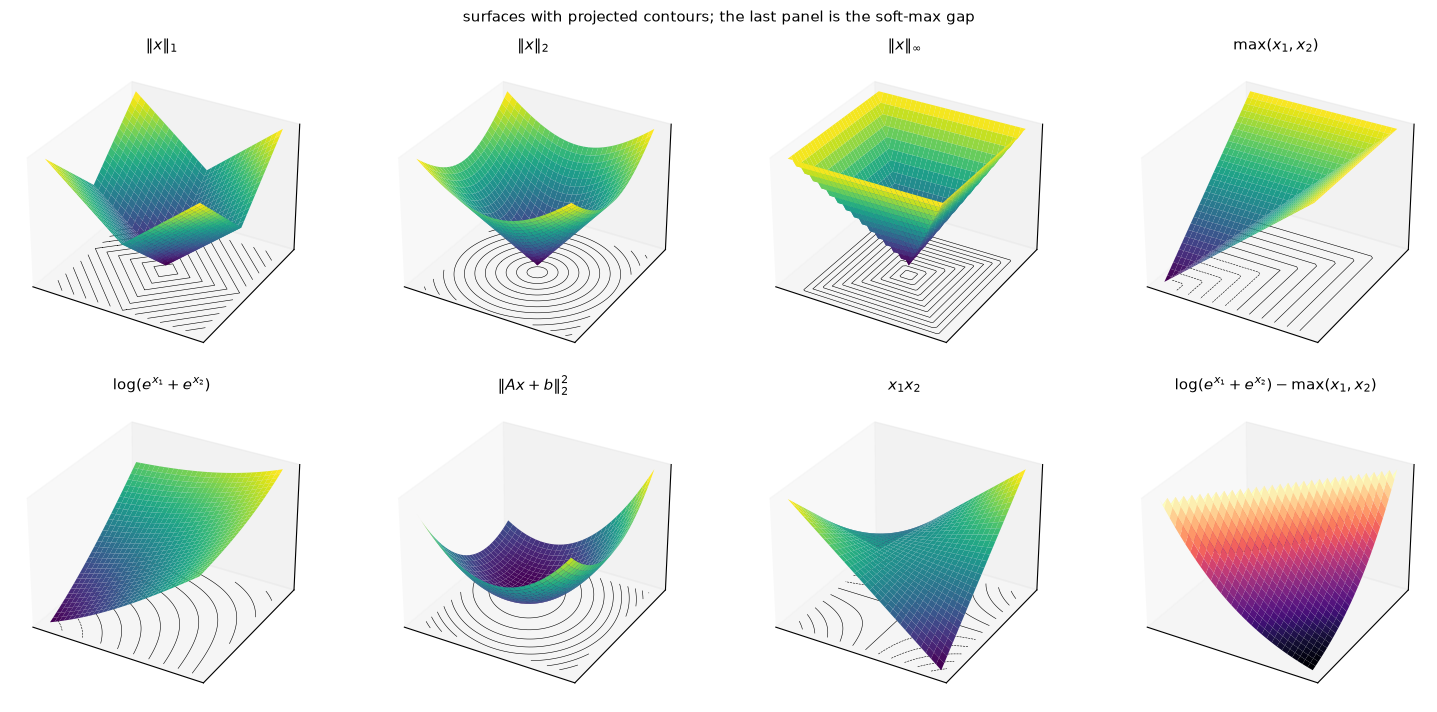

max of the gap over the box: 0.693147, log 2 = 0.693147


In [6]:
fig = plt.figure(figsize=(15.0, 7.2))
gs = np.linspace(-1.2, 1.2, 61)
Xs, Ys = np.meshgrid(gs, gs)
for k, (lab, f) in enumerate(funs):
    ax = fig.add_subplot(2, 4, k+1, projection="3d")
    Zs = np.array([[f(np.array([xx, yy])) for xx in gs] for yy in gs])
    ax.plot_surface(Xs, Ys, Zs, cmap="viridis", linewidth=0, antialiased=True,
                    rstride=2, cstride=2)
    ax.contour(Xs, Ys, Zs, levels=12, colors="k", linewidths=0.4, offset=Zs.min()-0.1)
    ax.set_title(lab, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax = fig.add_subplot(2, 4, 8, projection="3d")
Zg = np.array([[logsumexp(np.array([xx, yy])) - max(xx, yy) for xx in gs] for yy in gs])
ax.plot_surface(Xs, Ys, Zg, cmap="magma", linewidth=0, antialiased=True,
                rstride=2, cstride=2)
ax.set_title(r"$\log(e^{x_1}+e^{x_2})-\max(x_1,x_2)$", fontsize=11)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle("surfaces with projected contours; the last panel is the soft-max gap", fontsize=11)
fig.tight_layout()
plt.show()
print("max of the gap over the box: %.6f, log 2 = %.6f" % (Zg.max(), np.log(2)))

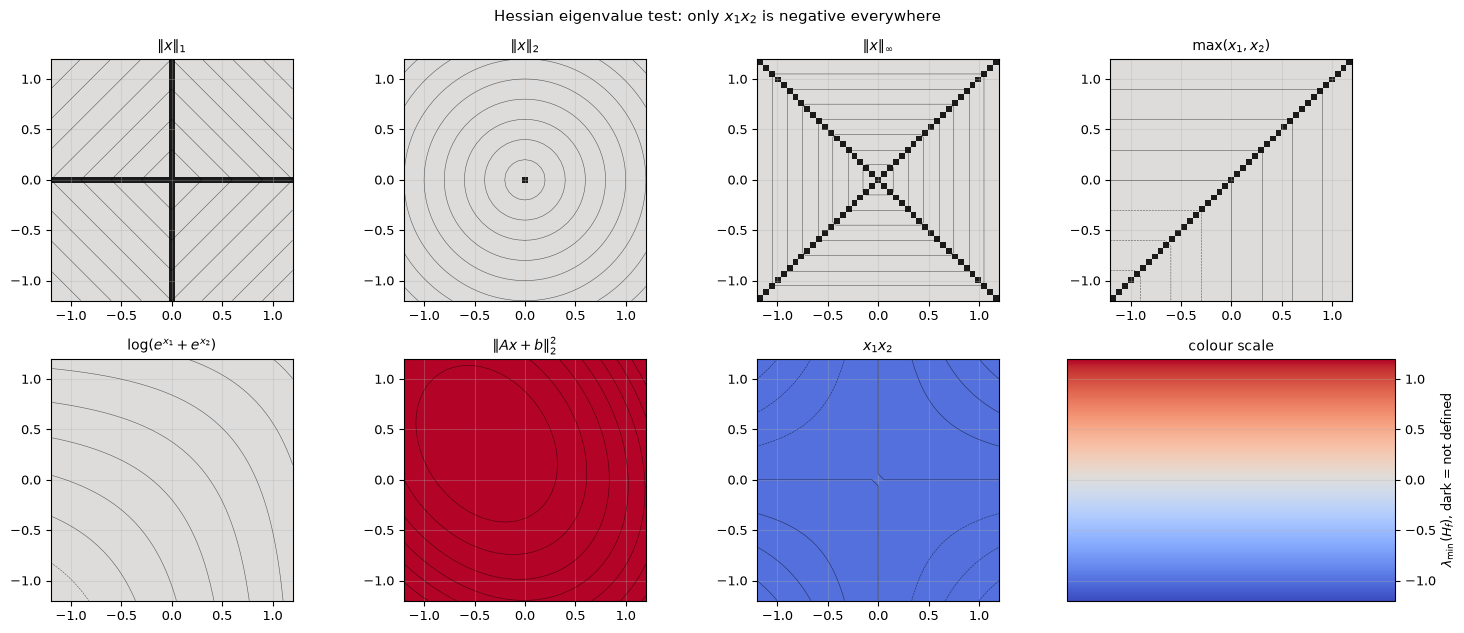

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15.0, 6.4))
axes = axes.ravel()
cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("#1a1a1a")
for k, ((lab, f), lam) in enumerate(zip(funs, lams)):
    ax = axes[k]
    Zc = np.array([[f(np.array([xx, yy])) for xx in g1] for yy in g1])
    im = ax.imshow(np.ma.masked_invalid(lam), origin="lower", extent=[-1.2, 1.2, -1.2, 1.2],
                   cmap=cmap, vmin=-1.2, vmax=1.2)
    ax.contour(Xg, Yg, Zc, levels=8, colors="k", linewidths=0.4, alpha=0.6)
    ax.set_title(lab, fontsize=10)
    ax.set_aspect("equal")
cb = fig.colorbar(im, cax=axes[7])
cb.set_label(r"$\lambda_{\min}(H_f)$, dark = not defined")
axes[7].set_title("colour scale", fontsize=10)
fig.suptitle(r"Hessian eigenvalue test: only $x_1x_2$ is negative everywhere", fontsize=11)
fig.tight_layout()
plt.show()

In [8]:
# --- x1*x2: convex in each variable, not along the ray (0,0) + t(1,-1)
t = np.linspace(-1.0, 1.0, 201)
ray = t * (-t)
assert np.allclose(ray, -t**2)
second = (ray[2:] - 2*ray[1:-1] + ray[:-2]) / (t[1] - t[0])**2
print("along the ray f(t,-t) = -t^2: second difference =", np.round(second[:3], 6))
assert np.allclose(second, -2.0, atol=1e-6)

h = 1e-3
for y0 in (-0.7, 0.4):                       # fixed y: x -> x*y0 is linear
    g = lambda s, y0=y0: s*y0
    d2 = (g(0.3 + h) - 2*g(0.3) + g(0.3 - h)) / h**2
    assert abs(d2) < 1e-8
for x0 in (-0.5, 0.8):                       # fixed x: y -> x0*y is linear
    g = lambda s, x0=x0: x0*s
    d2 = (g(0.2 + h) - 2*g(0.2) + g(0.2 - h)) / h**2
    assert abs(d2) < 1e-8
print("fixed y: x -> xy is linear; fixed x: y -> xy is linear: second differences 0")

# --- log-sum-exp versus max
pts = rng.uniform(-3, 3, size=(20000, 2))
gap = logsumexp(pts, axis=1) - pts.max(axis=1)
assert np.all(gap >= -1e-12) and np.all(gap <= np.log(2) + 1e-12)
print("max(x) <= logsumexp(x) <= max(x) + log 2: gap in [%.2e, %.6f], log 2 = %.6f"
      % (gap.min(), gap.max(), np.log(2)))

x0 = np.zeros(2)
H_plus = hess_fd(lambda p: logsumexp(p), x0, h=1e-3)
H_minus = hess_fd(lambda p: -logsumexp(p), x0, h=1e-3)
print("at x = 0: eig of H(+lse) =", np.round(np.linalg.eigvalsh(H_plus), 6),
      "  eig of H(-lse) =", np.round(np.linalg.eigvalsh(H_minus), 6))
assert np.allclose(np.linalg.eigvalsh(H_plus), [0.0, 0.5], atol=1e-5)
assert np.allclose(np.linalg.eigvalsh(H_minus), [-0.5, 0.0], atol=1e-5)
print("the convex function is +log-sum-exp: the minus sign in [CO 8.2] is a typo")

along the ray f(t,-t) = -t^2: second difference = [-2. -2. -2.]
fixed y: x -> xy is linear; fixed x: y -> xy is linear: second differences 0
max(x) <= logsumexp(x) <= max(x) + log 2: gap in [2.52e-03, 0.693086], log 2 = 0.693147
at x = 0: eig of H(+lse) = [0.  0.5]   eig of H(-lse) = [-0.5  0. ]
the convex function is +log-sum-exp: the minus sign in [CO 8.2] is a typo


### Explain

Convex: $\|x\|_1,\|x\|_2,\|x\|_\infty,\max$, log-sum-exp and $\|Ax+b\|_2^2$. The
colouring gives $\lambda_{\min}\ge0$ at every point where the Hessian exists.

Because doesn't have spikes.


## 4.3 $-\log\det X$ on positive definite matrices [CO 6.3, 8.3]

### Task

On the slice $X=\left[\begin{smallmatrix}x&z\\z&y\end{smallmatrix}\right]$ with
$z$ fixed, plot $-\log\det X$ over the region where $X\succ0$. Then pick a
random $Z\succ0$ and a symmetric $V$, and plot $g(t)=-\log\det(Z+tV)$ on the
interval where $Z+tV\succ0$, together with the formula of [CO 8.3]

$$g(t)=-\log\det Z-\sum_i\log(1+t\lambda_i),\qquad
\lambda_i=\operatorname{eig}(Z^{-1/2}VZ^{-1/2}).$$

### Explore

Use $n=5$ and many random rays. Where does $g$ blow up? Choose $V\succeq0$, then
$V$ indefinite.

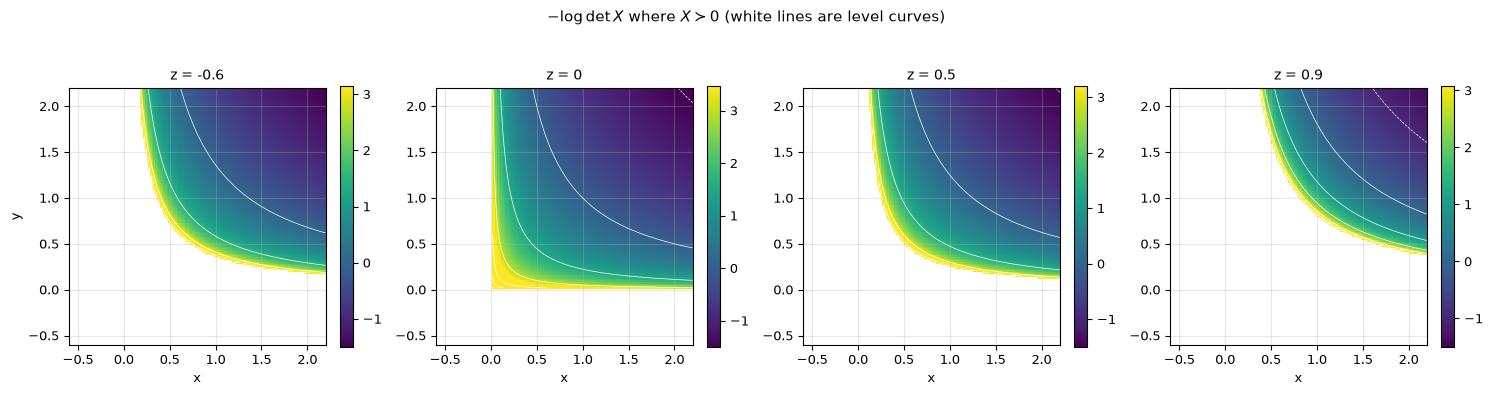

In [9]:
xs = np.linspace(-2.2, 2.2, 241)
Xg3, Yg3 = np.meshgrid(xs, xs)
zs = [-0.6, 0.0, 0.5, 0.9]

fig, axes = plt.subplots(1, 4, figsize=(15.0, 4.0))
for ax, z in zip(axes, zs):
    det = Xg3*Yg3 - z**2
    pd = (det > 0) & (Xg3 + Yg3 > 0)          # X > 0  <=>  det > 0 and trace > 0
    F = -np.log(np.where(pd, det, 1.0))
    Fm = np.ma.masked_where(~pd, F)
    vmax = np.percentile(F[pd], 97)
    im = ax.pcolormesh(Xg3, Yg3, Fm, shading="auto", cmap="viridis", vmin=-1.5, vmax=vmax)
    ax.contour(Xg3, Yg3, Fm, levels=8, colors="w", linewidths=0.5)
    ax.set_title("z = %g" % z, fontsize=10)
    ax.set_aspect("equal"); ax.set_xlabel("x")
    ax.set_xlim(-0.6, 2.2); ax.set_ylim(-0.6, 2.2)
    fig.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_ylabel("y")
fig.suptitle(r"$-\log\det X$ where $X\succ0$ (white lines are level curves)", fontsize=11)
fig.tight_layout()
plt.show()

# the boundary of the PD region is xy = z^2: check a few points on it
for z in zs:
    yy = np.array([0.6, 1.0, 1.8])
    pts = np.column_stack([z**2/yy, yy])
    assert np.allclose([np.linalg.det(np.array([[p[0], z], [z, p[1]]])) for p in pts], 0)

In [10]:
def z_inv_sqrt(Z):
    d, Q = np.linalg.eigh(Z)
    return (Q / np.sqrt(d)) @ Q.T


def ray_data(Z, V):
    """Eigenvalues of Z^{-1/2} V Z^{-1/2} and the interval where Z + tV > 0."""
    Zi = z_inv_sqrt(Z)
    lam = np.linalg.eigvalsh(Zi @ V @ Zi)
    lo, hi = -np.inf, np.inf
    for l in lam:
        if l > 0:
            lo = max(lo, -1.0/l)
        elif l < 0:
            hi = min(hi, -1.0/l)
    return lam, lo, hi


def g_ray(t, Z, V):
    return -np.linalg.slogdet(Z + t*V)[1]


def rand_pd(n, shift=0.0):
    M = rng.normal(size=(n, n))
    return M @ M.T + (n + shift) * np.eye(n)


Z = np.array([[2.0, 0.5], [0.5, 1.0]])       # Z > 0
V = np.array([[0.6, 0.9], [0.9, -0.4]])      # symmetric, indefinite
lam, lo, hi = ray_data(Z, V)
print("eig(Z^{-1/2} V Z^{-1/2}) =", np.round(lam, 4), "  feasible t in (%.4f, %.4f)" % (lo, hi))

t2 = np.linspace(lo + 0.03*(hi-lo), hi - 0.03*(hi-lo), 400)
g2 = np.array([g_ray(tt, Z, V) for tt in t2])
formula = -np.linalg.slogdet(Z)[1] - np.log(1 + t2[:, None]*lam).sum(axis=1)
print("max |g(t) - formula| =", np.abs(g2 - formula).max())
assert np.allclose(g2, formula, atol=1e-10)
d2 = (lam**2 / (1 + t2[:, None]*lam)**2).sum(axis=1)
print("second derivative g'' in [%.3f, %.3f] > 0" % (d2.min(), d2.max()))
assert np.all(d2 > 0)
print("blow-up points t = -1/lambda:", np.round(-1/lam, 4))

eig(Z^{-1/2} V Z^{-1/2}) = [-1.1502  0.5216]   feasible t in (-1.9170, 0.8694)
max |g(t) - formula| = 7.771561172376096e-15
second derivative g'' in [1.030, 143.244] > 0
blow-up points t = -1/lambda: [ 0.8694 -1.917 ]


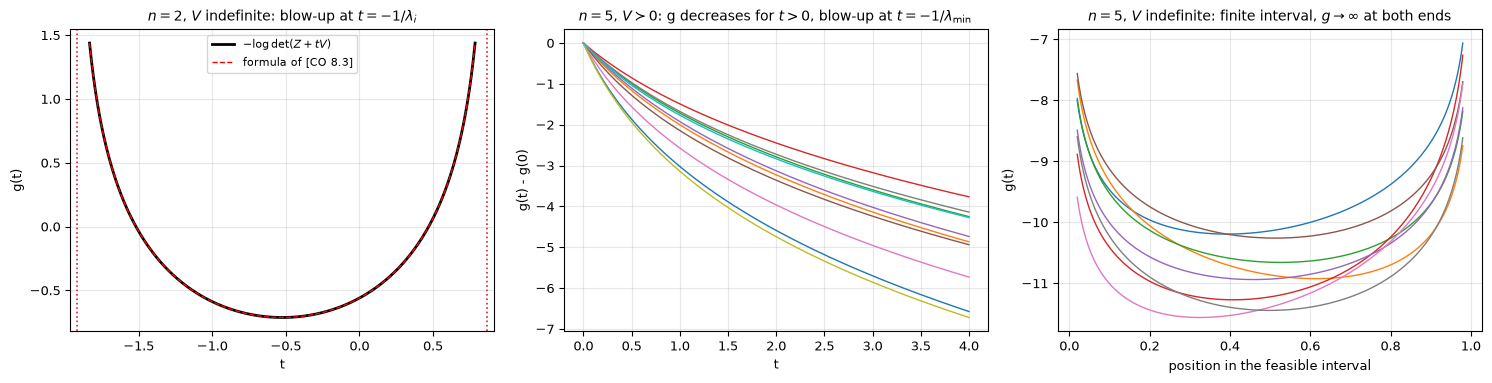

max |g - formula| over the n=5 positive definite rays: 7.11e-15


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 3.9))

ax = axes[0]
ax.plot(t2, g2, "k-", lw=2, label="$-\\log\\det(Z+tV)$")
ax.plot(t2, formula, "r--", lw=1, label="formula of [CO 8.3]")
for tb in (-1/lam):
    ax.axvline(tb, color="tab:red", ls=":", lw=1.2)
ax.set_xlabel("t"); ax.set_ylabel("g(t)")
ax.set_title(r"$n=2$, $V$ indefinite: blow-up at $t=-1/\lambda_i$", fontsize=10)
ax.legend(fontsize=8)

err = 0.0
ax = axes[1]
for _ in range(10):
    Z5, R = rand_pd(5), rng.normal(size=(5, 5))
    V5 = R @ R.T                                        # V > 0
    lam5, lo5, _ = ray_data(Z5, V5)
    tt = np.linspace(0, 4, 300)
    ax.plot(tt, [g_ray(x, Z5, V5) - g_ray(0, Z5, V5) for x in tt], lw=1)
    exact = -np.linalg.slogdet(Z5)[1] - np.log(1 + tt[:, None]*lam5).sum(axis=1)
    err = max(err, np.abs([g_ray(x, Z5, V5) for x in tt] - exact).max())
ax.set_xlabel("t"); ax.set_ylabel("g(t) - g(0)")
ax.set_title(r"$n=5$, $V\succ0$: g decreases for $t>0$, blow-up at $t=-1/\lambda_{\min}$", fontsize=10)

ax = axes[2]
for _ in range(10):
    Z5, R = rand_pd(5), rng.normal(size=(5, 5))
    V5 = R @ np.diag(rng.choice([-1.0, 1.0], 5)) @ R.T  # V indefinite
    lam5, lo5, hi5 = ray_data(Z5, V5)
    if not (np.isfinite(lo5) and np.isfinite(hi5)):
        continue
    s = np.linspace(0.02, 0.98, 300)
    tt = lo5 + s*(hi5 - lo5)
    ax.plot(s, [g_ray(x, Z5, V5) for x in tt], lw=1)
ax.set_xlabel("position in the feasible interval"); ax.set_ylabel("g(t)")
ax.set_title(r"$n=5$, $V$ indefinite: finite interval, $g\to\infty$ at both ends", fontsize=10)
fig.tight_layout()
plt.show()
print("max |g - formula| over the n=5 positive definite rays: %.2e" % err)
assert err < 1e-9

In [12]:
import ipywidgets as widgets


def draw_slice(z):
    det = Xg3*Yg3 - z**2
    pd = (det > 0) & (Xg3 + Yg3 > 0)
    Fq = np.ma.masked_where(~pd, -np.log(np.where(pd, det, 1.0)))
    fig, ax = plt.subplots(figsize=(5.6, 4.4))
    im = ax.pcolormesh(Xg3, Yg3, Fq, shading="auto", cmap="viridis",
                       vmin=-1.5, vmax=np.percentile(Fq.compressed(), 97))
    ax.contour(Xg3, Yg3, Fq, levels=8, colors="w", linewidths=0.5)
    ax.set_aspect("equal"); ax.set_xlim(-0.6, 2.2); ax.set_ylim(-0.6, 2.2)
    ax.set_title(r"$-\log\det X$ where $X\succ0$, $z=%.2f$" % z)
    fig.colorbar(im, ax=ax)
    plt.show()


show_slider(draw_slice, widgets.FloatSlider(value=0.5, min=-1.5, max=1.5, step=0.05,
                                            description="$z$", continuous_update=False))

### Explain

Any two points $x,y$ lie on the ray
$t\mapsto x+t(y-x)$, and convexity of that 1-D function at $t\in[0,1]$ is
exactly the chord inequality between $x$ and $y$. So "convex on every ray" says
the same thing as "convex on $\mathbb{R}^n$".

 $\log\det\Sigma$ is
twice the log-volume of the confidence ellipsoid.


## 4.4 $\lambda_{\max}(X)$ and $\lambda_{\min}(X)$ [CO 8.3, 9.3]

### Task

Use the slice $X=\left[\begin{smallmatrix}a+x&y\\y&a-x\end{smallmatrix}\right]$
with $a$ fixed by a slider and plot the surfaces $\lambda_{\max}(X)$ and
$\lambda_{\min}(X)$ over $(x,y)$. Then draw, for 20 unit vectors $u$, the planes
$u^\top Xu$ (linear in $X$) and show that $\lambda_{\max}$ is their upper
envelope:

$$\lambda_{\max}(X)=\sup_{\|u\|=1}u^\top Xu,\qquad
\lambda_{\min}(X)=\inf_{\|u\|=1}u^\top Xu.$$

### Explore

Find the closed form of both surfaces on this slice. For random $5\times5$
symmetric $X,Y$, check
$\lambda_{\max}(\lambda X+(1-\lambda)Y)\le\lambda\lambda_{\max}(X)+(1-\lambda)\lambda_{\max}(Y)$
on 1000 samples.

The slider in the last cell of this exercise sets the notebook variable $a$ and
redraws the 3-D panels of cell 21; the static figures are drawn at $a=0.6$.
It updates once per slider release (`continuous_update=False`), not at every
pixel, which is what keeps the panel smooth.


closed form lambda = a +- sqrt(x^2+y^2) vs eigvalsh: max error 4.440892098500626e-16


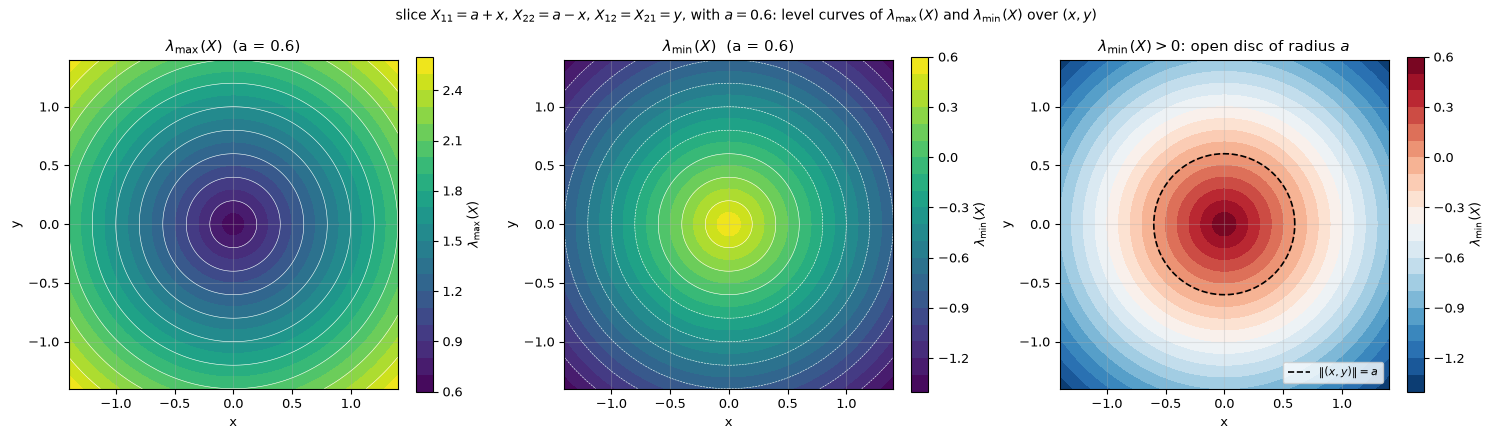

points where the two PD tests disagree: 0 of 200


In [13]:
a = 0.6
g4 = np.linspace(-1.4, 1.4, 121)
X4, Y4 = np.meshgrid(g4, g4)
Lmax = a + np.hypot(X4, Y4)          # closed form on the slice
Lmin = a - np.hypot(X4, Y4)

pts = rng.uniform(-1, 1, size=(200, 2))
num = np.array([np.linalg.eigvalsh(np.array([[a + p[0], p[1]], [p[1], a - p[0]]]))
                for p in pts])
ana = np.column_stack([a - np.hypot(pts[:, 0], pts[:, 1]),
                       a + np.hypot(pts[:, 0], pts[:, 1])])
print("closed form lambda = a +- sqrt(x^2+y^2) vs eigvalsh: max error", np.abs(num - ana).max())
assert np.allclose(num, ana)

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4))
for ax, F, lab in [(axes[0], Lmax, r"$\lambda_{\max}(X)$"),
                   (axes[1], Lmin, r"$\lambda_{\min}(X)$")]:
    cs = ax.contourf(X4, Y4, F, levels=20, cmap="viridis")
    ax.contour(X4, Y4, F, levels=10, colors="w", linewidths=0.4)
    ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(lab + "  (a = %.1f)" % a, fontsize=11)
    fig.colorbar(cs, ax=ax, fraction=0.046, label=lab)
ax = axes[2]
cs = ax.contourf(X4, Y4, Lmin, levels=20, cmap="RdBu_r")
th = np.linspace(0, 2*np.pi, 400)
ax.plot(a*np.cos(th), a*np.sin(th), "k--", lw=1.2, label=r"$\|(x,y)\|=a$")
ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(r"$\lambda_{\min}(X)>0$: open disc of radius $a$", fontsize=11)
ax.legend(fontsize=8, loc="lower right")
fig.colorbar(cs, ax=ax, fraction=0.046, label=r"$\lambda_{\min}(X)$")
fig.suptitle("slice $X_{11}=a+x$, $X_{22}=a-x$, $X_{12}=X_{21}=y$, with $a=%.1f$: "
             "level curves of $\\lambda_{\\max}(X)$ and $\\lambda_{\\min}(X)$ over $(x,y)$" % a,
             fontsize=10)
fig.tight_layout()
plt.show()

# on the slice, X > 0  <=>  sqrt(x^2+y^2) < a
pd_num = np.array([np.linalg.eigvalsh(np.array([[a + p[0], p[1]], [p[1], a - p[0]]])).min() > 0
                   for p in pts])
pd_ana = np.hypot(pts[:, 0], pts[:, 1]) < a
print("points where the two PD tests disagree:", int((pd_num != pd_ana).sum()), "of", len(pts))
assert np.array_equal(pd_num, pd_ana)

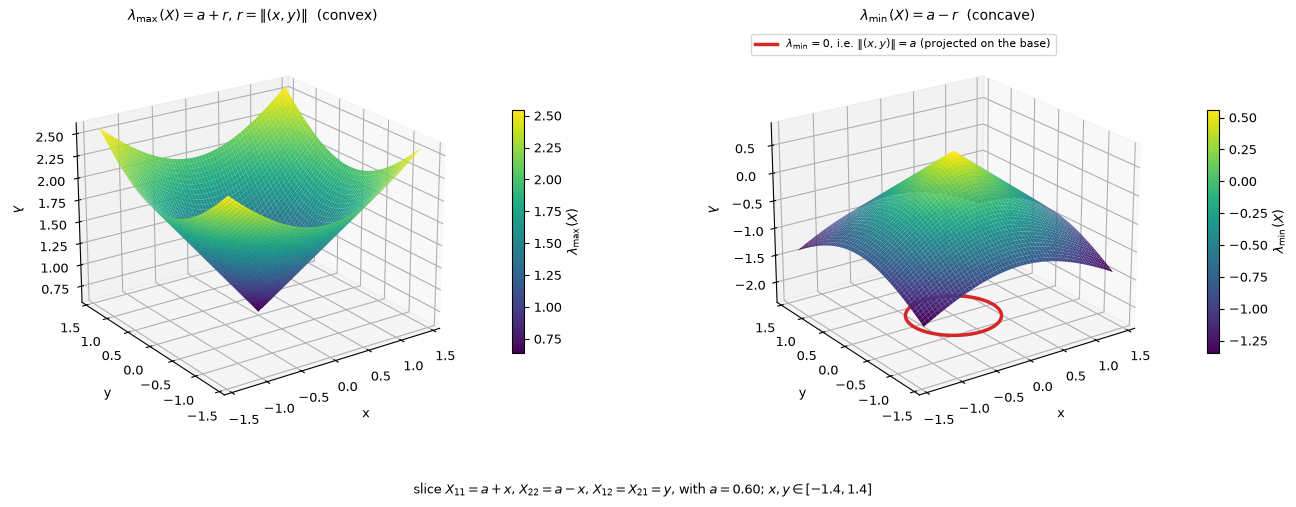

surfaces are exactly a +- r: max |lambda_max - (a+r)| = 0.0e+00, max |lambda_min - (a-r)| = 0.0e+00


In [14]:
# the same two surfaces in 3-D: x and y are the slice coordinates, the height is lambda
r4 = np.hypot(X4, Y4)
assert np.allclose(Lmax, a + r4) and np.allclose(Lmin, a - r4)


def plot_lambda_surfaces(a, X=X4, Y=Y4):
    """Two 3-D panels on the slice: lambda_max = a + r and lambda_min = a - r."""
    r = np.hypot(X, Y)
    fig = plt.figure(figsize=(13.5, 5.2))
    axs = []
    for k, (F, title, lab) in enumerate([
            (a + r, r"$\lambda_{\max}(X)=a+r$, $r=\|(x,y)\|$  (convex)",
             r"$\lambda_{\max}(X)$"),
            (a - r, r"$\lambda_{\min}(X)=a-r$  (concave)", r"$\lambda_{\min}(X)$")]):
        ax = fig.add_subplot(1, 2, k + 1, projection="3d")
        axs.append(ax)
        surf = ax.plot_surface(X, Y, F, cmap="viridis", linewidth=0, antialiased=True,
                               rstride=2, cstride=2)
        ax.set_xlabel("x", labelpad=8)
        ax.set_ylabel("y", labelpad=8)
        ax.set_zlabel(r"$\lambda$", labelpad=6)
        ax.set_title(title, fontsize=10)
        fig.colorbar(surf, ax=ax, shrink=0.60, pad=0.10, label=lab)
        ax.view_init(elev=22, azim=-125)

    # lambda_min = 0 on the circle r = a: there X loses rank, the boundary of the PD cone
    zmin = float((a - r).min()) - 1.0
    axs[1].set_zlim(zmin, float((a - r).max()) + 0.3)
    axs[1].contour(X, Y, a - r, levels=[0.0], zdir="z", offset=zmin,
                   colors="tab:red", linewidths=2.5)
    axs[1].plot([], [], color="tab:red", lw=2.5,
                label=r"$\lambda_{\min}=0$, i.e. $\|(x,y)\|=a$ (projected on the base)")
    axs[1].legend(fontsize=8, loc="upper left")
    fig.text(0.5, 0.015, "slice $X_{11}=a+x$, $X_{22}=a-x$, $X_{12}=X_{21}=y$, "
             "with $a=%.2f$; $x,y\\in[-1.4,1.4]$" % a, ha="center", fontsize=9)
    fig.subplots_adjust(top=0.91, bottom=0.13, left=0.05, right=0.98, wspace=0.24)
    plt.show()
    plt.close(fig)


plot_lambda_surfaces(a)
print("surfaces are exactly a +- r: max |lambda_max - (a+r)| = %.1e, "
      "max |lambda_min - (a-r)| = %.1e"
      % (np.abs(Lmax - (a + r4)).max(), np.abs(Lmin - (a - r4)).max()))

envelope <= lambda_max: True   max gap (20 directions) = 0.0244


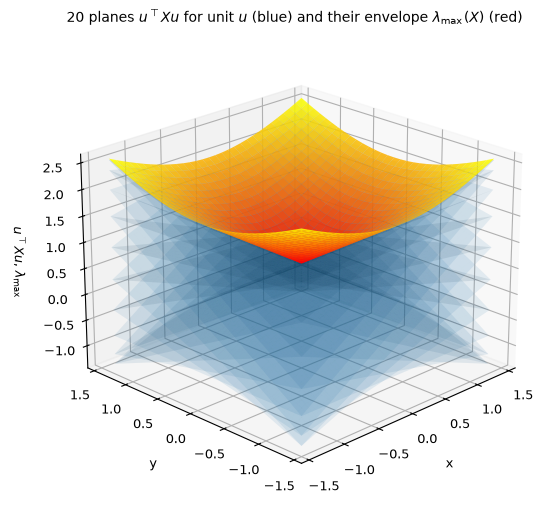

max violation of lambda_max(convex combination) <= combination: -3.35e-04
max violation of the concavity of lambda_min:                  -2.07e-04
at X = I, E = diag(1,-1): right derivative 1.0000, left derivative -1.0000


In [15]:
from matplotlib.patches import Patch

theta = np.linspace(0, np.pi, 20, endpoint=False)   # u and -u give the same plane
U = np.column_stack([np.cos(theta), np.sin(theta)])
planes = np.array([a + X4*(u[0]**2 - u[1]**2) + 2*u[0]*u[1]*Y4 for u in U])
env = planes.max(axis=0)
gap = Lmax - env
print("envelope <= lambda_max:", bool((gap >= -1e-12).all()),
      "  max gap (20 directions) = %.4f" % gap.max())
assert (gap >= -1e-12).all()

fig = plt.figure(figsize=(8.0, 6.2))
ax = fig.add_subplot(projection="3d")
for pl in planes:
    ax.plot_surface(X4, Y4, pl, color="tab:blue", alpha=0.10, linewidth=0,
                    antialiased=True, rstride=6, cstride=6)
ax.plot_surface(X4, Y4, Lmax, cmap="autumn", alpha=0.85, linewidth=0,
                antialiased=True, rstride=4, cstride=4)
ax.set_xlabel("x", labelpad=8)
ax.set_ylabel("y", labelpad=8)
ax.set_zlabel(r"$u^\top Xu$, $\lambda_{\max}$", labelpad=6)
ax.set_title(r"20 planes $u^\top Xu$ for unit $u$ (blue) and their envelope "
             r"$\lambda_{\max}(X)$ (red)", fontsize=10)
ax.view_init(elev=22, azim=-135)
plt.show()

# 1000 random 5x5 symmetric pairs: subadditivity of lambda_max, concavity of lambda_min
Xs = rng.normal(size=(1000, 5, 5)); Xs = (Xs + Xs.transpose(0, 2, 1))/2
Ys = rng.normal(size=(1000, 5, 5)); Ys = (Ys + Ys.transpose(0, 2, 1))/2
lam_s = rng.uniform(0, 1, size=1000)
mix = lam_s[:, None, None]*Xs + (1-lam_s[:, None, None])*Ys
lmax = np.linalg.eigvalsh(mix)[:, -1]
rhs = lam_s*np.linalg.eigvalsh(Xs)[:, -1] + (1-lam_s)*np.linalg.eigvalsh(Ys)[:, -1]
print("max violation of lambda_max(convex combination) <= combination: %.2e" % (lmax - rhs).max())
assert (lmax <= rhs + 1e-10).all()
lmin = np.linalg.eigvalsh(mix)[:, 0]
rmin = lam_s*np.linalg.eigvalsh(Xs)[:, 0] + (1-lam_s)*np.linalg.eigvalsh(Ys)[:, 0]
print("max violation of the concavity of lambda_min:                  %.2e" % (rmin - lmin).max())
assert (lmin >= rmin - 1e-10).all()

# repeated eigenvalue: no gradient
E = np.diag([1.0, -1.0]); h = 1e-6
right = (np.linalg.eigvalsh(np.eye(2) + h*E)[-1] - 1)/h
left = (np.linalg.eigvalsh(np.eye(2) - h*E)[-1] - 1)/(-h)
print("at X = I, E = diag(1,-1): right derivative %.4f, left derivative %.4f" % (right, left))

In [16]:
import ipywidgets as widgets


def draw_lambda_3d(a):
    """Redraw the 3-D panels for the current a; one call per slider release."""
    plot_lambda_surfaces(a)
    print("a = %.2f  ->  lambda_min(0,0) = %.2f, PD part is the open disc of radius %.2f"
          % (a, a, max(a, 0.0)))


# continuous_update=False: one redraw when the slider is released, not one per pixel
show_slider(draw_lambda_3d, widgets.FloatSlider(value=a, min=-0.5, max=1.5, step=0.05,
                                                description="$a$", continuous_update=False))

### Explain

Because it is like intersection of epigraphs. 

Because it has a local maximum that it is its global maximum.

At a repeated eigenvalue the maximum is not differentiable: at $X=I$ with
$E=\operatorname{diag}(1,-1)$ the right derivative is $+1$ and the left one
$-1$. The eigenvectors are then not unique but span the whole eigenspace.

The PD part of the slice is the open disc of radius $a$ (empty for $a\le0$).


## 4.5 $\operatorname{tr}(SX)$ and the Gaussian log-likelihood [CO 12.4, 13.4]

### Task

Fix $S\succ0$ ($2\times2$). On the PSD cone of Exercise 3.3, plot the level sets
of the linear function $X\mapsto\operatorname{tr}(SX)$. Then plot, on a 2-D
slice, the function

$$h(X)=-\log\det X+\operatorname{tr}(SX),\qquad X\succ0,$$

and find its minimiser numerically. Check that it is $X^\star=S^{-1}$.

### Explore

Sample $X,S\succeq0$ at random and check $\operatorname{tr}(SX)\ge0$; find an
indefinite pair with $\operatorname{tr}(SX)<0$.

eigenvalues of S: [0.719 2.281]
S^{-1} =
 [[ 0.609756 -0.365854]
 [-0.365854  1.219512]]
min tr(SX) on the drawn cone: 0.0  (>= 0)


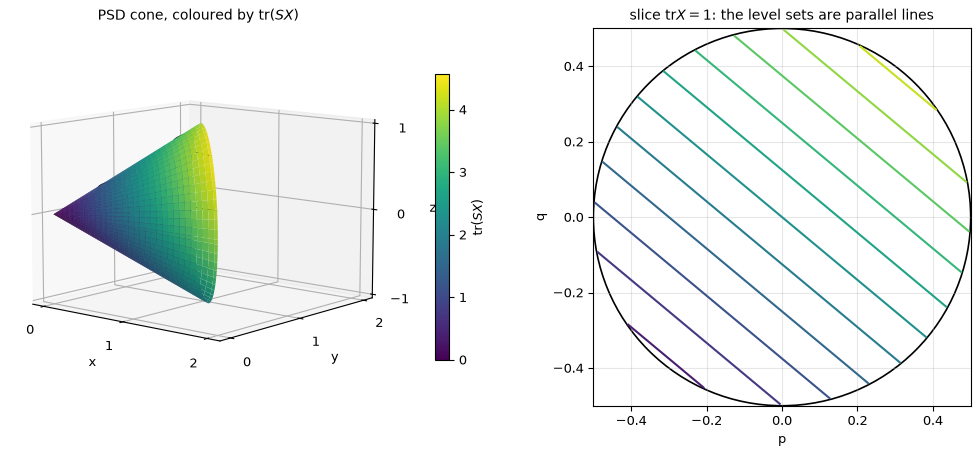

In [17]:
S = np.array([[2.0, 0.6], [0.6, 1.0]])
print("eigenvalues of S:", np.round(np.linalg.eigvalsh(S), 4))
print("S^{-1} =\n", np.round(np.linalg.inv(S), 6))

# cone boundary: trace = s, det = 0, parametrised by the angle phi
s_v = np.linspace(0, 2.0, 60)
phi = np.linspace(0, 2*np.pi, 120)
Sg, Pg = np.meshgrid(s_v, phi)
Xc = Sg*(1 + np.cos(Pg))/2
Yc = Sg*(1 - np.cos(Pg))/2
Zc = Sg*np.sin(Pg)/2
Tcone = S[0, 0]*Xc + 2*S[0, 1]*Zc + S[1, 1]*Yc
print("min tr(SX) on the drawn cone:", Tcone.min(), " (>= 0)")

fig = plt.figure(figsize=(13.5, 4.9))
ax = fig.add_subplot(1, 2, 1, projection="3d")
norm = plt.Normalize(Tcone.min(), Tcone.max())
ax.plot_surface(Xc, Yc, Zc, facecolors=plt.cm.viridis(norm(Tcone)),
                rstride=2, cstride=2, linewidth=0, antialiased=True)
ax.contour(Xc, Yc, Zc, levels=[0.3, 0.8, 1.3, 1.8], colors="k", linewidths=0.8)
ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2]); ax.set_zticks([-1, 0, 1])
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title(r"PSD cone, coloured by $\mathrm{tr}(SX)$", fontsize=10)
ax.view_init(elev=10, azim=-50)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, fraction=0.03,
             pad=0.1, label=r"$\mathrm{tr}(SX)$")

ax2 = fig.add_subplot(1, 2, 2)
pp = np.linspace(-0.5, 0.5, 300)
PP, QQ = np.meshgrid(pp, pp)
disc = PP**2 + QQ**2 < 0.25
lev = S[0, 0]*(0.5 + PP) + 2*S[0, 1]*QQ + S[1, 1]*(0.5 - PP)
ax2.contour(PP, QQ, np.ma.masked_where(~disc, lev), levels=12, cmap="viridis")
ax2.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="k", lw=1.2))
ax2.set_aspect("equal"); ax2.set_xlabel("p"); ax2.set_ylabel("q")
ax2.set_title(r"slice $\mathrm{tr}X=1$: the level sets are parallel lines", fontsize=10)
plt.show()

minimiser X_hat =
 [[ 0.609756 -0.365854]
 [-0.365854  1.219512]]
S^{-1} =
 [[ 0.609756 -0.365854]
 [-0.365854  1.219512]]
max |X_hat - S^{-1}| = 1.28e-08,  max |grad h| = 2.25e-08
h(X_hat) = 2.494696,  log det S + 2 = 2.494696


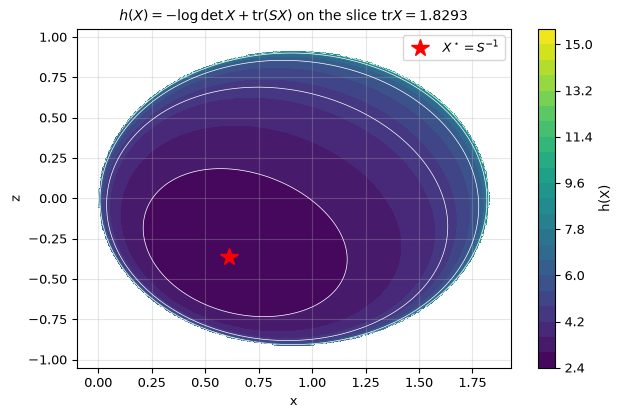

In [18]:
def X_of(l):
    L = np.array([[l[0], 0.0], [l[1], l[2]]])      # X = L L^T is PD for any l
    return L @ L.T


def h_params(l):
    X = X_of(l)
    return -np.linalg.slogdet(X)[1] + np.trace(S @ X)


res = optimize.minimize(h_params, x0=np.array([1.0, 0.0, 1.0]), method="BFGS",
                        options=dict(gtol=1e-12))
X_hat = X_of(res.x)
grad = -np.linalg.inv(X_hat) + S
print("minimiser X_hat =\n", np.round(X_hat, 6))
print("S^{-1} =\n", np.round(np.linalg.inv(S), 6))
print("max |X_hat - S^{-1}| = %.2e,  max |grad h| = %.2e" % (np.abs(X_hat - np.linalg.inv(S)).max(),
                                                            np.abs(grad).max()))
assert np.allclose(X_hat, np.linalg.inv(S), atol=1e-6)
assert np.abs(grad).max() < 1e-6
print("h(X_hat) = %.6f,  log det S + 2 = %.6f"
      % (h_params(res.x), np.linalg.slogdet(S)[1] + 2))

# h on the slice tr X = tr S^{-1}, which contains X^*
T1 = np.trace(np.linalg.inv(S))
xx = np.linspace(-0.1, T1 + 0.1, 300)
zz = np.linspace(-1.05, 1.05, 300)
XX, ZZ = np.meshgrid(xx, zz)
DET = XX*(T1 - XX) - ZZ**2
pds = DET > 0
H = -np.log(np.where(pds, DET, 1.0)) + S[0, 0]*XX + 2*S[0, 1]*ZZ + S[1, 1]*(T1 - XX)
Hm = np.ma.masked_where(~pds, H)

fig, ax = plt.subplots(figsize=(7.0, 4.4))
cs = ax.contourf(XX, ZZ, Hm, levels=25, cmap="viridis")
ax.contour(XX, ZZ, Hm, levels=12, colors="w", linewidths=0.5)
ax.plot(X_hat[0, 0], X_hat[0, 1], "r*", ms=13, label=r"$X^\star=S^{-1}$")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title(r"$h(X)=-\log\det X+\mathrm{tr}(SX)$ on the slice $\mathrm{tr}X=%.4f$" % T1,
             fontsize=10)
ax.legend(fontsize=9)
fig.colorbar(cs, ax=ax, label="h(X)")
plt.show()
assert np.isclose(np.trace(X_hat), T1)

In [19]:
def rand_psd(n):
    M = rng.normal(size=(n, n))
    return M @ M.T


trs = np.array([np.trace(rand_psd(2) @ rand_psd(2)) for _ in range(2000)])
print("2000 random PSD pairs: tr(SX) in [%.2e, %.3f], all >= 0: %s"
      % (trs.min(), trs.max(), bool((trs >= 0).all())))
assert (trs >= 0).all()
Xp = np.array([[1.0, 0.0], [0.0, 2.0]])
Sm = np.array([[1.0, 0.0], [0.0, -1.0]])
print("PSD X with indefinite S: tr(SX) = %.1f, eigenvalues of S = %s"
      % (np.trace(Sm @ Xp), np.linalg.eigvalsh(Sm)))
assert np.trace(Sm @ Xp) < 0


def sym_basis2(i, j):
    E = np.zeros((2, 2))
    if i == j:
        E[i, i] = 1.0
    else:
        E[i, j] = E[j, i] = 0.5
    return E


def hess_sym(fun, M, h=1e-5):
    basis = [sym_basis2(0, 0), sym_basis2(0, 1), sym_basis2(1, 1)]
    Hm_ = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            Hm_[i, j] = (fun(M + h*basis[i] + h*basis[j]) - fun(M + h*basis[i] - h*basis[j])
                         - fun(M - h*basis[i] + h*basis[j]) + fun(M - h*basis[i] - h*basis[j]))/(4*h*h)
    return Hm_


loglik_theta = lambda Th: np.linalg.slogdet(Th)[1] - np.trace(Th @ S)
loglik_sigma = lambda Sig: -np.linalg.slogdet(Sig)[1] - np.trace(np.linalg.solve(Sig, S))

spec_theta = np.linalg.eigvalsh(hess_sym(loglik_theta, np.linalg.inv(S)))
spec_sig = np.linalg.eigvalsh(hess_sym(loglik_sigma, S))
spec_sig4 = np.linalg.eigvalsh(hess_sym(loglik_sigma, 4*S))
print("spectrum in Theta = S^{-1}:", np.round(spec_theta, 4))
print("spectrum in Sigma = S:      ", np.round(spec_sig, 4))
print("spectrum in Sigma = 4S:     ", np.round(spec_sig4, 4))
assert (spec_theta < 0).all()
assert (spec_sig4 > 0).all()

2000 random PSD pairs: tr(SX) in [1.85e-02, 128.637], all >= 0: True
PSD X with indefinite S: tr(SX) = -1.0, eigenvalues of S = [-1.  1.]
spectrum in Theta = S^{-1}: [-4.527  -1.2692 -0.3839]
spectrum in Sigma = S:       [-1.6831 -0.4719 -0.1427]
spectrum in Sigma = 4S:      [0.0045 0.0147 0.0526]


### Explain

Because $\operatorname{tr}(SX)$ it is a linear function.

**Why $\operatorname{tr}(SX)\ge0$ for $S,X\succeq0$ [CO 12.4].** Write
$S=\sum_i\lambda_i u_iu_i^\top$ with $\lambda_i\ge0$. Then
$\operatorname{tr}(SX)=\sum_i\lambda_i\,u_i^\top Xu_i\ge0$, because
$u_i^\top Xu_i\ge0$ for $X\succeq0$. The 2000 random PSD pairs give values in
$[1.9\times10^{-2},128.6]$; an indefinite $S$ with $X\succeq0$ gives $-1$.

**Why minimising $h$ is ML for the precision [CO 13.4].** In 2.4 the Gaussian
log-likelihood per sample, with $\Theta=\Sigma^{-1}$ and $S$ the sample
covariance, is
$\frac1m\ell=\text{const}+\frac12\log\det\Theta-\frac12\operatorname{tr}(\Theta S)$,
so maximising it is minimising
$h(\Theta)=-\log\det\Theta+\operatorname{tr}(\Theta S)$. Then
$\nabla h=-\Theta^{-1}+S$ vanishes at $\Theta=S^{-1}$, found numerically to
$1.3\times10^{-8}$ (where $h=2.494696=\log\det S+2$). It is concave in $\Theta$
(Hessian eigenvalues $-4.53,-1.27,-0.38$), not in $\Sigma$: at $\Sigma=S$ they
are $-1.68,-0.47,-0.14$, but at $\Sigma=4S$ they are $+0.005,+0.015,+0.053$, so
one maximises in $\Theta$.


## 4.6 Operations that preserve convexity and Jensen [CO 9.1–9.7]

### Task

Build functions with the rules of [CO 9]: $\|Ax+b\|_2^2$,
$\max_i(a_i^\top x+b_i)$ (plot the piecewise-linear surface), $e^{g(x)}$ with
$g$ convex, $1/g(x)$ with $g$ concave and positive. Then, for $f(x)=e^x$ and a
random discrete $X$, check $f(EX)\le Ef(X)$ [CO 9.7] and visualise it with the
chord picture.

### Explain

For each function, which rule certifies convexity? Find an example where
composing a convex $h$ with a convex $g$ is not convex.

$\|Ax+b\|_2^2$                 lambda_min in [1.9216, 1.9216], undefined 0 of 1681 points


$\max_i(a_i^\top x+b_i)$       lambda_min in [-0.0000, 0.0000], undefined 1 of 1681 points


$e^{g(x)}$, $g$ convex         lambda_min in [0.7883, 4.0429], undefined 0 of 1681 points


$1/g(x)$, $g$ concave $>0$     lambda_min in [0.2734, 2.4358], undefined 0 of 1681 points


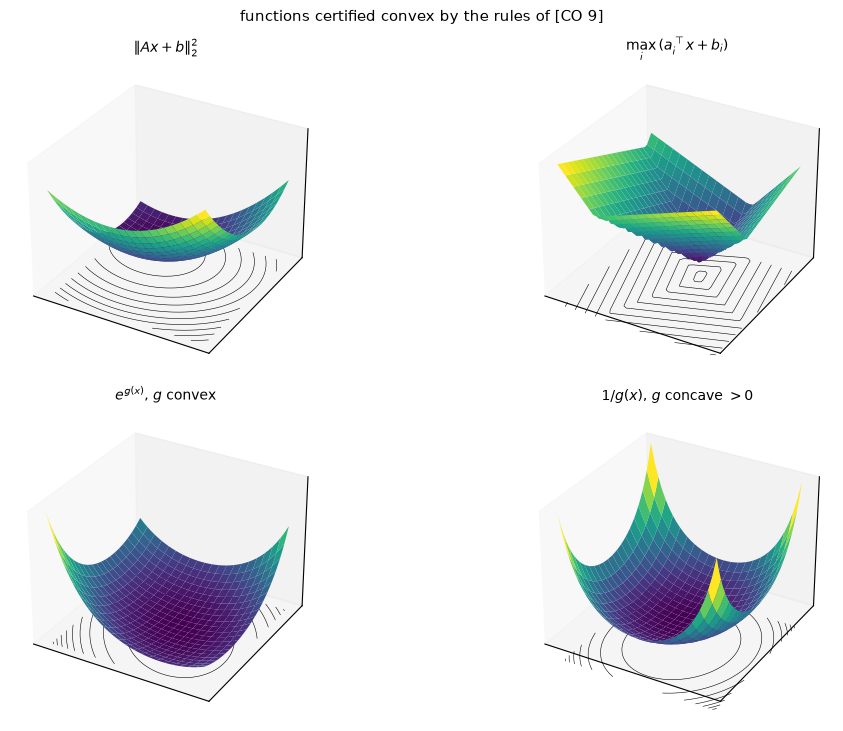

segment test $\|Ax+b\|^2$               worst violation -1.96e-04
segment test $\max_i(a_i^\top x+b_i)$   worst violation  4.44e-16
segment test $e^{g}$                    worst violation -1.29e-04
segment test $1/g$                      worst violation -2.60e-05


In [20]:
A6 = np.array([[1.0, 0.4], [-0.2, 1.1]])
b6 = np.array([0.3, -0.7])
Arow = np.array([[1.0, 0.2], [-0.4, 1.0], [0.3, -0.9], [-1.0, -0.3], [0.1, 1.2]])
brow = np.array([0.1, -0.2, 0.5, 0.4, -0.6])
Q6 = np.array([[1.0, 0.3], [0.3, 0.8]])
c6 = np.array([0.2, -0.1])

g_exp = lambda p: 0.5*(p - c6) @ Q6 @ (p - c6) + 0.3      # convex
g_conc = lambda p: 1.6 - 0.5*p[0]**2 - 0.35*p[1]**2       # concave, > 0 on the box
fs6 = [(r"$\|Ax+b\|_2^2$", lambda p: np.sum((A6 @ p + b6)**2)),
       (r"$\max_i(a_i^\top x+b_i)$", lambda p: np.max(Arow @ p + brow)),
       (r"$e^{g(x)}$, $g$ convex", lambda p: np.exp(g_exp(p))),
       (r"$1/g(x)$, $g$ concave $>0$", lambda p: 1.0/g_conc(p))]

gs6 = np.linspace(-1.1, 1.1, 41)
X6, Y6 = np.meshgrid(gs6, gs6)
for lab, f in fs6:
    lam6 = lam_min_grid(f, X6, Y6)
    fin = lam6[np.isfinite(lam6)]
    print("%-30s lambda_min in [%.4f, %.4f], undefined %d of %d points"
          % (lab, fin.min(), fin.max(), int(np.isnan(lam6).sum()), lam6.size))

fig = plt.figure(figsize=(12.0, 7.4))
for k, (lab, f) in enumerate(fs6):
    ax = fig.add_subplot(2, 2, k+1, projection="3d")
    Zs = np.array([[f(np.array([x, y])) for x in gs6] for y in gs6])
    ax.plot_surface(X6, Y6, Zs, cmap="viridis", linewidth=0, antialiased=True,
                    rstride=2, cstride=2)
    ax.contour(X6, Y6, Zs, levels=10, colors="k", linewidths=0.4, offset=Zs.min()-0.2)
    ax.set_title(lab, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle("functions certified convex by the rules of [CO 9]", fontsize=11)
fig.tight_layout()
plt.show()

# convexity of the piecewise-linear one by the segment test (the Hessian is 0 inside each piece)
f_quad_v = lambda P: np.sum((P @ A6.T + b6)**2, axis=1)
f_max_v = lambda P: (P @ Arow.T + brow).max(axis=1)
f_exp_v = lambda P: np.exp(0.5*np.einsum("ni,ij,nj->n", P - c6, Q6, P - c6) + 0.3)
f_inv_v = lambda P: 1.0/(1.6 - 0.5*P[:, 0]**2 - 0.35*P[:, 1]**2)
pa = rng.uniform(-1, 1, size=(500, 2)); pb = rng.uniform(-1, 1, size=(500, 2))
lam_s = rng.uniform(0, 1, size=(500, 1))
for lab, fv in [(r"$\|Ax+b\|^2$", f_quad_v), (r"$\max_i(a_i^\top x+b_i)$", f_max_v),
                (r"$e^{g}$", f_exp_v), (r"$1/g$", f_inv_v)]:
    v = fv(lam_s*pa + (1-lam_s)*pb) - (lam_s[:, 0]*fv(pa) + (1-lam_s[:, 0])*fv(pb))
    print("segment test %-26s worst violation % .2e" % (lab, v.max()))
    assert v.max() <= 1e-10

E X = 1.0500, f(E X) = 2.8577, E f(X) = 3.5118, gap = 0.6541


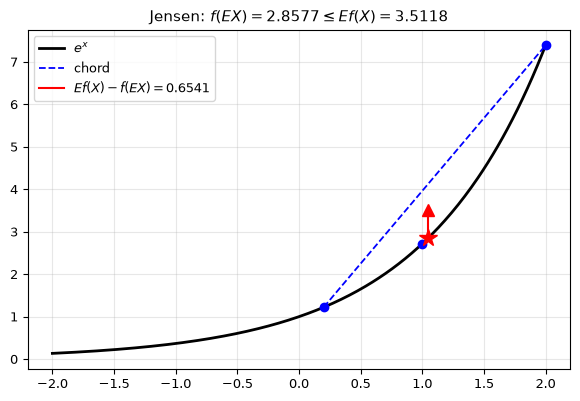

In [21]:
Xv = np.array([0.2, 1.0, 2.0])
pv = np.array([0.25, 0.5, 0.25])
EX, EfX, fEX = pv @ Xv, pv @ np.exp(Xv), np.exp(pv @ Xv)
print("E X = %.4f, f(E X) = %.4f, E f(X) = %.4f, gap = %.4f" % (EX, fEX, EfX, EfX - fEX))
assert fEX <= EfX

gx = np.linspace(-2.0, 2.0, 300)
fig, ax = plt.subplots(figsize=(7.0, 4.4))
ax.plot(gx, np.exp(gx), "k-", lw=2, label="$e^x$")
ax.plot([Xv.min(), Xv.max()], np.exp([Xv.min(), Xv.max()]), "b--", lw=1.3, label="chord")
ax.plot(Xv, np.exp(Xv), "bo", ms=6)
ax.plot([EX, EX], [fEX, EfX], "r-", lw=1.5, label=r"$E f(X)-f(EX)=%.4f$" % (EfX - fEX))
ax.plot(EX, fEX, "r*", ms=13)
ax.plot(EX, EfX, "r^", ms=8)
ax.set_title(r"Jensen: $f(EX)=%.4f \leq Ef(X)=%.4f$" % (fEX, EfX), fontsize=11)
ax.legend(fontsize=9)
plt.show()

h''(y) = e^{-y} > 0 at y = 1: 0.3679 (h convex)
(h o g)''(0) = -2.0000  ->  not convex


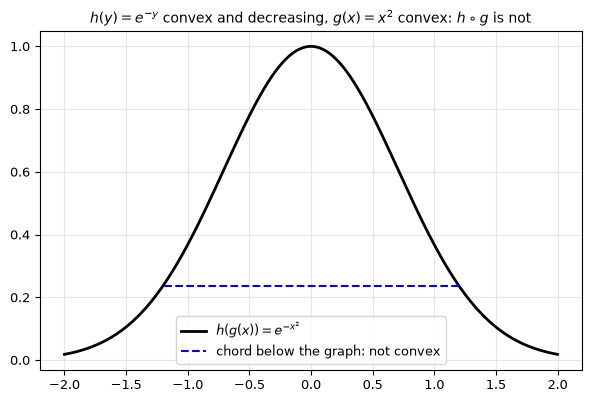

In [22]:
h_ce = lambda y: np.exp(-y)
gg = lambda x: x**2
print("h''(y) = e^{-y} > 0 at y = 1: %.4f (h convex)" % h_ce(1.0))
d2 = (h_ce(gg(1e-4)) - 2*h_ce(gg(0.0)) + h_ce(gg(-1e-4)))/1e-8
print("(h o g)''(0) = %.4f  ->  not convex" % d2)
assert d2 < 0

fig, ax = plt.subplots(figsize=(7.0, 4.4))
ax.plot(gx, h_ce(gg(gx)), "k-", lw=2, label=r"$h(g(x))=e^{-x^2}$")
x1, x2 = -1.2, 1.2
lamj = np.linspace(0, 1, 100)
ax.plot(lamj*x1 + (1-lamj)*x2, lamj*h_ce(gg(x1)) + (1-lamj)*h_ce(gg(x2)),
        "b--", label="chord below the graph: not convex")
ax.set_title(r"$h(y)=e^{-y}$ convex and decreasing, $g(x)=x^2$ convex: $h\circ g$ is not", fontsize=10)
ax.legend(fontsize=9)
plt.show()

### Explain

$\|Ax+b\|_2^2$ is an affine map followed by $t\mapsto t^2$, convex and
nondecreasing on $t\ge0$ [CO 9.1, 9.6]; $\max_i(a_i^\top x+b_i)$ is a pointwise
maximum of affine functions [CO 9.3]; $e^{g}$ composes the convex nondecreasing
$\exp$ with convex $g$, and $1/g$ composes the convex nonincreasing $1/t$ on
$t>0$ with a concave positive $g$ [CO 9.5]. 

$h(y)=e^{-y}$ is convex, $g(x)=x^2$ is
convex, but $h(g(x))=e^{-x^2}$ has second derivative $(4x^2-2)e^{-x^2}$,
equal to $-2$ at $0$, and its chord lies below the graph. They both are convex but h is decreasing.
